In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/kermany2018")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'kermany2018' dataset.
Path to dataset files: /kaggle/input/kermany2018


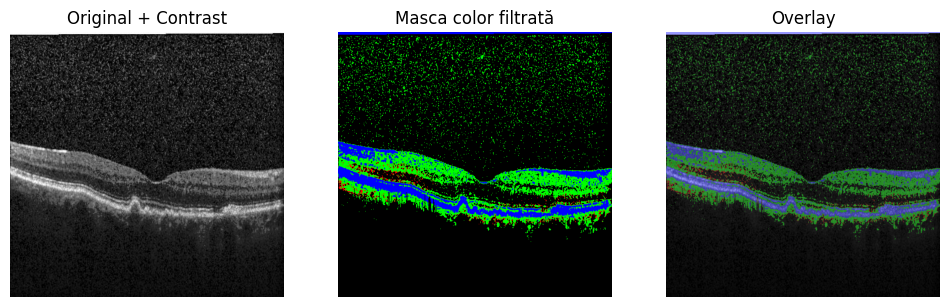

In [34]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# === Load imagine ===
img_path = "/kaggle/input/kermany2018/OCT2017 /test/DRUSEN/DRUSEN-1912508-1.jpeg"

# Load grayscale
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"Imaginea nu a fost găsită: {img_path}")

# === Contrast doar pentru pixelii > black_thresh ===
black_thresh = 50
mask_nonblack = img > black_thresh

clahe = cv2.createCLAHE(clipLimit=1.0, tileGridSize=(8,8))
contrast_img = img.copy()
contrast_img[mask_nonblack] = clahe.apply(img)[mask_nonblack]

# === Intervalele și culorile pentru masca color ===
intervals = [0, 60, 70, 120, 256]
color_map = [
    (0, 0, 0),         # negru
    (255, 0, 0),       # roșu
    (0, 255, 0),       # verde
    (0, 0, 255),       # albastru
]

# === Creează masca color inițială ===
mask_color = np.zeros((img.shape[0], img.shape[1], 3), dtype=np.uint8)
for i in range(len(intervals)-1):
    mask = (contrast_img >= intervals[i]) & (contrast_img < intervals[i+1])
    mask_color[mask] = color_map[i]

# === Filtrare sus/albastru și jos/roșu ===
blue_mask = (mask_color[:,:,2] == 255)  # pixel albastru
red_mask  = (mask_color[:,:,0] == 255)  # pixel roșu

H, W = img.shape
new_mask = mask_color.copy()

for x in range(W):
    # === Sus/albastru ===
    col_blue = np.where(blue_mask[:, x])[0]
    if len(col_blue) > 0:
        top_blue = col_blue.min()
        ys = np.arange(H)
        mask_filter_blue = ys >= top_blue - 30
    else:
        mask_filter_blue = np.ones(H, dtype=bool)

    # === Jos/rosu ===
    col_red = np.where(red_mask[:, x])[0]
    if len(col_red) > 0:
        bottom_red = col_red.max()
        ys = np.arange(H)
        mask_filter_red = ys <= bottom_red + 40
    else:
        mask_filter_red = np.ones(H, dtype=bool)

    # === Combinare sus/jos ===
    final_mask = mask_filter_blue & mask_filter_red
    new_mask[:, x] = new_mask[:, x] * final_mask[:, None]

# === Overlay peste imaginea originală ===
orig_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
overlay = cv2.addWeighted(orig_rgb, 0.6, new_mask, 0.4, 0)

# === Afișare ===
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Original + Contrast")
plt.imshow(contrast_img, cmap="gray")
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Masca color filtrată")
plt.imshow(new_mask)
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Overlay")
plt.imshow(overlay)
plt.axis("off")

plt.show()


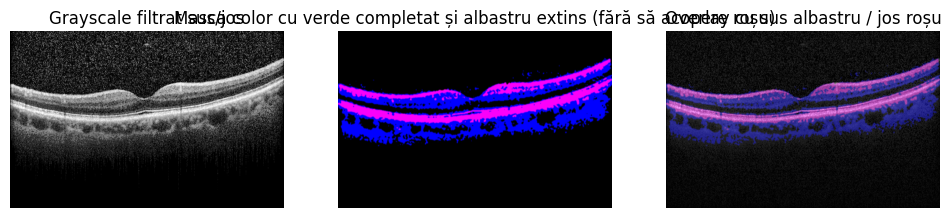

In [204]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# === Load imagine ===
img_path = "/kaggle/input/kermany2018/OCT2017 /test/NORMAL/NORMAL-1025847-1.jpeg"
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"Imaginea nu a fost găsită: {img_path}")

# === Contrast CLAHE doar pentru pixelii > black_thresh ===
black_thresh = 60
mask_nonblack = img > black_thresh

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
contrast_img = img.copy()
contrast_img[mask_nonblack] = clahe.apply(img)[mask_nonblack]

H, W = img.shape
processed_img = contrast_img.copy()




# === 1️⃣ Filtrare sus/jos pe baza pixelilor negri în grayscale ===
for x in range(W):
    col = contrast_img[:, x]
    indices_nonblack = np.where(col > black_thresh)[0]
    if len(indices_nonblack) > 0:
        top = indices_nonblack.min()
        bottom = indices_nonblack.max()
        ys = np.arange(H)
        mask_filter = (ys >= top - 30) & (ys <= bottom + 50)
        processed_img[:, x] = processed_img[:, x] * mask_filter
    else:
        processed_img[:, x] = 0

# === 2️⃣ Creează masca color pe baza intensității filtrate ===
intervals = [0, 80, 110, 110,160, 256]
color_map = [
    (0, 0, 0),         # negru
    (0, 255, 0),        # verde
    (255, 0, 0),      # roșu
    (0, 0, 255),       # albastru
    (250,0,250),
]

mask_color = np.zeros((H, W, 3), dtype=np.uint8)
for i in range(len(intervals)-1):
    mask = (processed_img >= intervals[i]) & (processed_img < intervals[i+1])
    mask_color[mask] = color_map[i]



# === 2.5️⃣ Completează verde între verde dacă nu e albastru între ele (fără să acopere roșu) ===
for x in range(W):
    col = mask_color[:, x]
    green_indices = np.where(col[:,1]==255)[0]
    blue_indices  = np.where(col[:,2]==255)[0]
    red_indices   = np.where(col[:,0]==255)[0]

    if len(green_indices) > 1:
        for i in range(len(green_indices)-1):
            start = green_indices[i]
            end   = green_indices[i+1]
            # dacă între ele nu e albastru
            if not np.any(np.isin(np.arange(start+1, end), blue_indices)):
                for y in range(start+1, end):
                    if y not in red_indices:  # nu acoperim roșu
                        col[y,:] = (0, 255, 0)




    # === Extindere albastru până la margini dacă nu este legat de margine (fără să acopere roșu) ===
    col_blue_indices = np.where(col[:,2]==255)[0]
    if len(col_blue_indices) > 0:
        top_blue = col_blue_indices.min()
        bottom_blue = col_blue_indices.max()
        for y in range(0, top_blue):
            if y not in red_indices:
                col[y,:] = (80,10,10)
        for y in range(bottom_blue+1, H):
            if y not in red_indices:
                col[y,:] = (80,10,10)

    mask_color[:, x] = col



# === 3️⃣ Filtrare suplimentară sus/albastru și jos/rosu pe masca color ===
blue_mask = (mask_color[:,:,1] == 255)
red_mask  = (mask_color[:,:,1] == 255)

new_mask = mask_color.copy()

for x in range(W):
    # Sus/albastru
    col_blue = np.where(blue_mask[:, x])[0]
    if len(col_blue) > 0:
        top_blue = col_blue.min()
        ys = np.arange(H)
        mask_filter_blue = ys >= top_blue - 30
    else:
        mask_filter_blue = np.ones(H, dtype=bool)

    # Jos/rosu
    col_red = np.where(red_mask[:, x])[0]
    if len(col_red) > 0:
        bottom_red = col_red.max()
        ys = np.arange(H)
        mask_filter_red = ys <= bottom_red + 40
    else:
        mask_filter_red = np.ones(H, dtype=bool)

    # Combinare sus/jos
    final_mask = mask_filter_blue & mask_filter_red
    new_mask[:, x] = new_mask[:, x] * final_mask[:, None]

# === 4️⃣ Transformăm pixelii rămași negri în verde (fără să atingem roșu sau albastru) ===
black_pixels = (new_mask[:,:,0]==0) & (new_mask[:,:,1]==0) & (new_mask[:,:,2]==0)
new_mask[black_pixels] = (0, 225, 0)




green_pixels = (new_mask[:,:,0] == 0) & (new_mask[:,:,1] >= 200) & (new_mask[:,:,2] == 0)
new_mask[green_pixels] = (0,0,0)

brown_pixels = (new_mask[:,:,0] == 80) & (new_mask[:,:,1] == 10) & (new_mask[:,:,2] == 10)
new_mask[brown_pixels] = (0,0,0)





# ==== Kernel pentru extindere ====
kernel_size = 3   # ajustează după nevoie: 5 -> 2 pixeli, 7 -> 3 pixeli etc.
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))

# ==== Roz ====
pink_mask = (new_mask[:,:,0] > 200) & (new_mask[:,:,1] < 80) & (new_mask[:,:,2] > 200)
pink_uint8 = pink_mask.astype(np.uint8) * 255

pink_dilated = cv2.dilate(pink_uint8, kernel)
new_pink_zone = (pink_dilated == 255) & (~pink_mask)  # doar extindere

# NU suprascriem albastru
blue_mask = (new_mask[:,:,0] < 50) & (new_mask[:,:,1] < 50) & (new_mask[:,:,2] > 200)
new_pink_zone[blue_mask] = False

# aplicăm roz
new_mask[new_pink_zone] = (255, 0, 255)

# ==== Albastru ====
blue_mask = (new_mask[:,:,0] < 50) & (new_mask[:,:,1] < 50) & (new_mask[:,:,2] > 200)
blue_uint8 = blue_mask.astype(np.uint8) * 255

blue_dilated = cv2.dilate(blue_uint8, kernel)
new_blue_zone = (blue_dilated == 255) & (~blue_mask)  # doar extindere

# NU suprascriem roz
pink_mask = (new_mask[:,:,0] > 200) & (new_mask[:,:,1] < 80) & (new_mask[:,:,2] > 200)
new_blue_zone[pink_mask] = False

# aplicăm albastru
new_mask[new_blue_zone] = (0, 0, 255)









smoothed = cv2.medianBlur(new_mask, 5)   # netezire contururi dure
smoothed = cv2.GaussianBlur(smoothed, (3,5), 0)  # înmuiere fină

new_mask = smoothed























# === 4️⃣ Overlay peste imaginea originală ===
orig_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
overlay = cv2.addWeighted(orig_rgb, 0.6, new_mask, 0.4, 0)

# === Afișare ===
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.title("Grayscale filtrat sus/jos")
plt.imshow(processed_img, cmap="gray")
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Masca color cu verde completat și albastru extins (fără să acopere roșu)")
plt.imshow(new_mask)
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Overlay cu sus albastru / jos roșu")
plt.imshow(overlay)
plt.axis("off")

plt.show()


In [208]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# ==== Setări generale ====
kernel_size = 3
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
black_thresh = 60
intervals = [0, 80, 110, 110,160, 256]
color_map = [
    (0, 0, 0),         # negru
    (0, 255, 0),       # verde
    (255, 0, 0),       # roșu
    (0, 0, 255),       # albastru
    (250,0,250),       # roz
]

# ==== Funcție procesare imagine ====
def process_image(img_path):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Imaginea nu a fost găsită: {img_path}")
    H, W = img.shape

    # === Contrast CLAHE doar pentru pixelii > black_thresh ===
    mask_nonblack = img > black_thresh
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    contrast_img = img.copy()
    contrast_img[mask_nonblack] = clahe.apply(img)[mask_nonblack]
    processed_img = contrast_img.copy()

    # === 1️⃣ Filtrare sus/jos pe baza pixelilor negri în grayscale ===
    for x in range(W):
        col = contrast_img[:, x]
        indices_nonblack = np.where(col > black_thresh)[0]
        if len(indices_nonblack) > 0:
            top = indices_nonblack.min()
            bottom = indices_nonblack.max()
            ys = np.arange(H)
            mask_filter = (ys >= top - 30) & (ys <= bottom + 50)
            processed_img[:, x] = processed_img[:, x] * mask_filter
        else:
            processed_img[:, x] = 0

    # === 2️⃣ Creează masca color pe baza intensității filtrate ===
    mask_color = np.zeros((H, W, 3), dtype=np.uint8)
    for i in range(len(intervals)-1):
        mask = (processed_img >= intervals[i]) & (processed_img < intervals[i+1])
        mask_color[mask] = color_map[i]

    # === 2.5️⃣ Completează verde între verde dacă nu e albastru între ele (fără să acopere roșu) ===
    for x in range(W):
        col = mask_color[:, x]
        green_indices = np.where(col[:,1]==255)[0]
        blue_indices  = np.where(col[:,2]==255)[0]
        red_indices   = np.where(col[:,0]==255)[0]

        if len(green_indices) > 1:
            for i in range(len(green_indices)-1):
                start = green_indices[i]
                end   = green_indices[i+1]
                if not np.any(np.isin(np.arange(start+1, end), blue_indices)):
                    for y in range(start+1, end):
                        if y not in red_indices:
                            col[y,:] = (0, 255, 0)

        # === Extindere albastru până la margini dacă nu este legat de margine (fără să acopere roșu) ===
        col_blue_indices = np.where(col[:,2]==255)[0]
        if len(col_blue_indices) > 0:
            top_blue = col_blue_indices.min()
            bottom_blue = col_blue_indices.max()
            for y in range(0, top_blue):
                if y not in red_indices:
                    col[y,:] = (80,10,10)
            for y in range(bottom_blue+1, H):
                if y not in red_indices:
                    col[y,:] = (80,10,10)

        mask_color[:, x] = col

    # === 3️⃣ Filtrare suplimentară sus/albastru și jos/rosu pe masca color ===
    blue_mask = (mask_color[:,:,1] == 255)
    red_mask  = (mask_color[:,:,1] == 255)
    new_mask = mask_color.copy()

    for x in range(W):
        col_blue = np.where(blue_mask[:, x])[0]
        if len(col_blue) > 0:
            top_blue = col_blue.min()
            ys = np.arange(H)
            mask_filter_blue = ys >= top_blue - 30
        else:
            mask_filter_blue = np.ones(H, dtype=bool)

        col_red = np.where(red_mask[:, x])[0]
        if len(col_red) > 0:
            bottom_red = col_red.max()
            ys = np.arange(H)
            mask_filter_red = ys <= bottom_red + 40
        else:
            mask_filter_red = np.ones(H, dtype=bool)

        final_mask = mask_filter_blue & mask_filter_red
        new_mask[:, x] = new_mask[:, x] * final_mask[:, None]

    # === 4️⃣ Transformăm pixelii rămași negri în verde (fără să atingem roșu sau albastru) ===
    black_pixels = (new_mask[:,:,0]==0) & (new_mask[:,:,1]==0) & (new_mask[:,:,2]==0)
    new_mask[black_pixels] = (0, 225, 0)

    green_pixels = (new_mask[:,:,0] == 0) & (new_mask[:,:,1] >= 200) & (new_mask[:,:,2] == 0)
    new_mask[green_pixels] = (0,0,0)

    brown_pixels = (new_mask[:,:,0] == 80) & (new_mask[:,:,1] == 10) & (new_mask[:,:,2] == 10)
    new_mask[brown_pixels] = (0,0,0)

    # ==== Roz ====
    pink_mask = (new_mask[:,:,0] > 200) & (new_mask[:,:,1] < 80) & (new_mask[:,:,2] > 200)
    pink_uint8 = pink_mask.astype(np.uint8) * 255
    pink_dilated = cv2.dilate(pink_uint8, kernel)
    new_pink_zone = (pink_dilated == 255) & (~pink_mask)

    blue_mask = (new_mask[:,:,0] < 50) & (new_mask[:,:,1] < 50) & (new_mask[:,:,2] > 200)
    new_pink_zone[blue_mask] = False
    new_mask[new_pink_zone] = (255, 0, 255)

    # ==== Albastru ====
    blue_uint8 = blue_mask.astype(np.uint8) * 255
    blue_dilated = cv2.dilate(blue_uint8, kernel)
    new_blue_zone = (blue_dilated == 255) & (~blue_mask)

    pink_mask = (new_mask[:,:,0] > 200) & (new_mask[:,:,1] < 80) & (new_mask[:,:,2] > 200)
    new_blue_zone[pink_mask] = False
    new_mask[new_blue_zone] = (0, 0, 255)

    # ==== Netezire ====
    smoothed = cv2.medianBlur(new_mask, 5)
    smoothed = cv2.GaussianBlur(smoothed, (3,5), 0)
    new_mask = smoothed

    # ==== Overlay ====
    orig_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    overlay = cv2.addWeighted(orig_rgb, 0.6, new_mask, 0.4, 0)

    return processed_img, new_mask, overlay



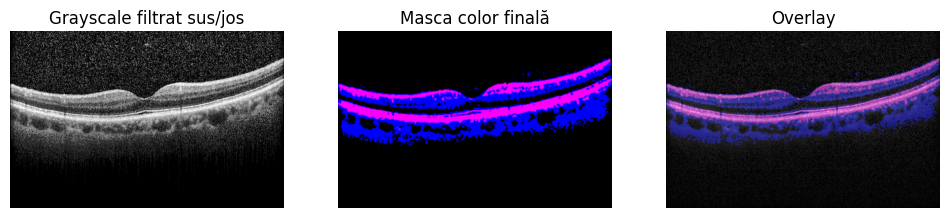

In [209]:
img_path = "/kaggle/input/kermany2018/OCT2017 /test/NORMAL/NORMAL-1025847-1.jpeg"
processed_img, mask_color, overlay = process_image(img_path)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.title("Grayscale filtrat sus/jos")
plt.imshow(processed_img, cmap="gray")
plt.axis("off")

plt.subplot(1,3,2)
plt.title("Masca color finală")
plt.imshow(mask_color)
plt.axis("off")

plt.subplot(1,3,3)
plt.title("Overlay")
plt.imshow(overlay)
plt.axis("off")
plt.show()


In [213]:
import os
from tqdm import tqdm
import cv2
import numpy as np

train_folder = "/kaggle/input/kermany2018/OCT2017 /train"
output_folder = "/kaggle/working/masks_train1"

# Folderele de procesat
categories = ["CNV", "DRUSEN", "NORMAL"]

os.makedirs(output_folder, exist_ok=True)

for category in categories:
    cat_folder = os.path.join(train_folder, category)
    out_cat_folder = os.path.join(output_folder, category)
    os.makedirs(out_cat_folder, exist_ok=True)

    # Luăm primele 3000 de imagini
    img_files = sorted(os.listdir(cat_folder))[:3000]

    for img_file in tqdm(img_files, desc=f"Processing {category}"):
        img_path = os.path.join(cat_folder, img_file)
        try:
            # Procesăm imaginea
            _, mask_color, _ = process_image(img_path)

            # Salvăm doar masca color
            base_name = os.path.splitext(img_file)[0]
            cv2.imwrite(os.path.join(out_cat_folder, f"{base_name}_mask.png"), mask_color)
        except Exception as e:
            print(f"Error processing {img_path}: {e}")


Processing NORMAL: 100%|██████████| 3000/3000 [1:31:40<00:00,  1.83s/it]


In [214]:
!du -sh "/kaggle/working/masks_train1"


533M	/kaggle/working/masks_train1


In [6]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


ValueError: Mountpoint must not already contain files

In [1]:
import os
os.makedirs("/content/drive/MyDrive/masks1", exist_ok=True)
